# Final Project: Speech-to-Text Prediction Using NLP
## File 1 — Model Building

Domain: Customer/product review **sentiment classification** (Positive / Negative / Neutral).

Workflow: Speech -> Text -> Preprocessing -> Text Vectorization -> ML Model -> Prediction + Confidence Score

### Step 1: Install and Import Libraries

In [1]:
import re
import string
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score
from wordcloud import WordCloud

%matplotlib inline

### Step 2: Data Collection

In [2]:
df = pd.read_csv("dataset.csv")
df.shape

(1356, 2)

### Step 3: Data Understanding

In [3]:
df.head()

,text,target
0,"Very unhappy with the customer support, worst ...",Negative
1,The seller exceeded all my expectations.,Positive
2,"This course is a standard option, does what it...",Neutral
3,"The packaging arrived as expected, no issues.",Neutral
4,"The seller is a standard option, does what it ...",Neutral


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1356 entries, 0 to 1355
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    1355 non-null   str  
 1   target  1356 non-null   str  
dtypes: str(2)
memory usage: 21.3 KB


In [5]:
df.isnull().sum()

text      1
target    0
dtype: int64

In [6]:
df["target"].value_counts()

target
Neutral     453
Positive    452
Negative    451
Name: count, dtype: int64

In [7]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 5


Clean the issues found above (missing text, duplicate rows) before moving on.

In [8]:
df = df.dropna(subset=["text"]).drop_duplicates().reset_index(drop=True)
df.shape

(1350, 2)

### Step 4: Text Feature Engineering

In [9]:
df["num_words"] = df["text"].apply(lambda x: len(str(x).split()))
df["num_chars"] = df["text"].apply(lambda x: len(str(x)))
df[["num_words", "num_chars"]].describe()

,num_words,num_chars
count,1350.000000,1350.000000
mean,8.022222,47.477778
std,1.092237,6.441666
min,6.000000,31.000000
25%,7.000000,43.000000
50%,8.000000,47.000000
75%,9.000000,52.000000
max,11.000000,69.000000


### Step 5: Word Cloud

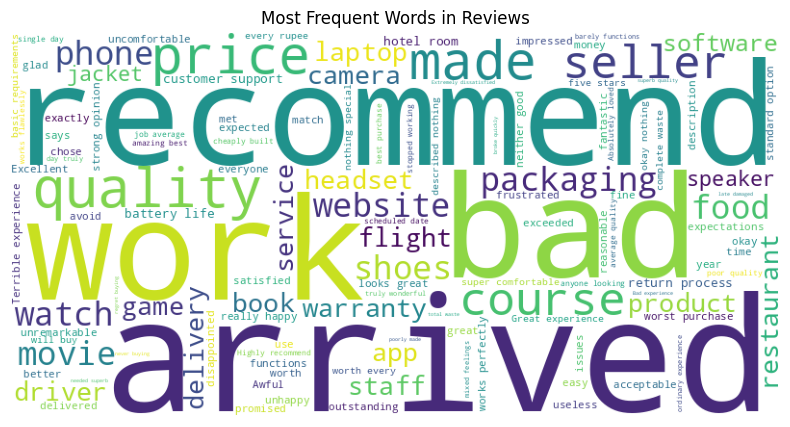

In [10]:
text_blob = " ".join(df["text"].astype(str))
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text_blob)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud)
plt.axis("off")
plt.title("Most Frequent Words in Reviews")
plt.show()

### Step 6: Text Preprocessing

Lowercasing, punctuation/number removal, stop-word removal, and lemmatization.

In [11]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", " ", text)
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(preprocess_text)
df[["text", "clean_text"]].head()

,text,clean_text
0,"Very unhappy with the customer support, worst ...",unhappy customer support worst purchase ever
1,The seller exceeded all my expectations.,seller exceeded expectation
2,"This course is a standard option, does what it...",course standard option say
3,"The packaging arrived as expected, no issues.",packaging arrived expected issue
4,"The seller is a standard option, does what it ...",seller standard option say


### Step 7: Input-Output Separation

In [12]:
X = df["clean_text"]
y = df["target"]

### Step 8: Train-Test Split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])

Train size: 1080 | Test size: 270


### Step 9: Text Vectorization (TF-IDF)

In [14]:
vectorizer = TfidfVectorizer(max_features=3000, ngram_range=(1, 2))
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)
X_train_vec.shape

(1080, 1503)

### Step 10: Baseline Model Building (Logistic Regression)

In [15]:
baseline_model = LogisticRegression(max_iter=1000)
baseline_model.fit(X_train_vec, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

### Step 11: Model Evaluation

In [16]:
y_pred_baseline = baseline_model.predict(X_test_vec)
print("Accuracy:", accuracy_score(y_test, y_pred_baseline))
print(classification_report(y_test, y_pred_baseline))

Accuracy: 1.0
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        90
     Neutral       1.00      1.00      1.00        90
    Positive       1.00      1.00      1.00        90

    accuracy                           1.00       270
   macro avg       1.00      1.00      1.00       270
weighted avg       1.00      1.00      1.00       270



### Step 12: Hyperparameter Tuning

GridSearchCV over Logistic Regression and KNN so the two candidate models can be compared fairly.

In [17]:
lr_params = {"C": [0.1, 1, 5, 10], "solver": ["lbfgs"]}
lr_grid = GridSearchCV(LogisticRegression(max_iter=1000), lr_params, cv=5, scoring="accuracy", n_jobs=-1)
lr_grid.fit(X_train_vec, y_train)
print("Best LR params:", lr_grid.best_params_, "| CV accuracy:", lr_grid.best_score_)

Best LR params: {'C': 0.1, 'solver': 'lbfgs'} | CV accuracy: 1.0


In [18]:
knn_params = {"n_neighbors": [3, 5, 7, 9, 11], "weights": ["uniform", "distance"]}
knn_grid = GridSearchCV(KNeighborsClassifier(), knn_params, cv=5, scoring="accuracy", n_jobs=-1)
knn_grid.fit(X_train_vec, y_train)
print("Best KNN params:", knn_grid.best_params_, "| CV accuracy:", knn_grid.best_score_)

Best KNN params: {'n_neighbors': 7, 'weights': 'uniform'} | CV accuracy: 0.9972222222222221


### Step 13: Best Model Selection

In [19]:
candidates = {
    "LogisticRegression": lr_grid.best_estimator_,
    "KNN": knn_grid.best_estimator_,
}

results = {}
for name, mdl in candidates.items():
    preds = mdl.predict(X_test_vec)
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average="weighted")
    results[name] = {"accuracy": acc, "f1_weighted": f1}
    print(f"{name} -> Accuracy: {acc:.4f}, Weighted F1: {f1:.4f}")

best_name = max(results, key=lambda n: results[n]["f1_weighted"])
best_model = candidates[best_name]
print("\nSelected best model:", best_name)
print(classification_report(y_test, best_model.predict(X_test_vec)))

LogisticRegression -> Accuracy: 1.0000, Weighted F1: 1.0000
KNN -> Accuracy: 0.9963, Weighted F1: 0.9963

Selected best model: LogisticRegression
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        90
     Neutral       1.00      1.00      1.00        90
    Positive       1.00      1.00      1.00        90

    accuracy                           1.00       270
   macro avg       1.00      1.00      1.00       270
weighted avg       1.00      1.00      1.00       270



### Step 14: Save the Model

In [20]:
joblib.dump(best_model, "best_model.pkl")
joblib.dump(vectorizer, "vectorizer.pkl")
print("Saved best_model.pkl and vectorizer.pkl")

Saved best_model.pkl and vectorizer.pkl


The project now contains `dataset.csv`, `best_model.pkl`, and `vectorizer.pkl`.

The Streamlit application (`app.py`) loads these two files, converts recorded speech to text, applies the same preprocessing + TF-IDF vectorizer, and returns the predicted sentiment with a confidence score. It also includes an optional MediaPipe hand-gesture detection tab as described in the project spec.